In [1]:
!pip install -q transformers==4.41.0
!pip install librosa
!pip install torchaudio
!pip install scikit-learn pandas matplotlib pyarrow
!pip install soundfile
!pip install datasets
!pip install torchcodec
!pip install xgboost

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 145.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 134.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 68.7 MB/s eta 0:00:00


In [2]:
import zipfile
import os
import math
import random
import numpy as np
import pandas as pd
from pathlib import Path
import torchcodec
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
import torchaudio
from transformers import Wav2Vec2Processor, AutoModel, AutoConfig, AutoModelForSequenceClassification
from transformers import AutoFeatureExtractor, Wav2Vec2Processor, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt


In [3]:
CSV_PATH = "/content/drive/MyDrive/szakdolgozat/augmented_metadata.csv"
AUDIO_BASE = "/content/SingMOS"
EMBED_CACHE_DIR = "/content/embeddings_cache"
zip_path = "/content/drive/MyDrive/szakdolgozat/augmented_wavs.zip.zip"
extract_path = "/content/SingMOS"
os.makedirs(EMBED_CACHE_DIR, exist_ok=True)

In [4]:
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [5]:
SAMPLE_RATE = 16000
BATCH_SIZE = 8
EMBED_BATCH_SIZE = 8
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

WAVLM_MODEL = "microsoft/wavlm-large"
FREEZE_WAVLM = True
EMBED_LAYER_POOLING = "mean"

# Regressor params
LR = 1e-4
EPOCHS = 40
HIDDEN_DIM = 512

In [6]:
df = pd.read_csv(CSV_PATH)

print("Rows:", len(df))
print(df.head())

# Stratified binning
df['mos_bin'] = pd.cut(df['mos'], bins=[0.9,1.5,2.5,3.5,4.5,5.1], labels=False)
train_df, test_df = train_test_split(df, test_size=0.15, random_state=42, stratify=df['mos_bin'])
train_df, val_df  = train_test_split(train_df, test_size=0.15, random_state=42, stratify=train_df['mos_bin'])

print("Train,Val,Test sizes:", len(train_df), len(val_df), len(test_df))

Rows: 7100
   Unnamed: 0                  wav  mos
0           0  sys0005-utt0405.wav  1.0
1           1  sys0005-utt0412.wav  1.0
2           2  sys0005-utt0416.wav  1.0
3           3  sys0005-utt0417.wav  1.0
4           4  sys0005-utt0448.wav  1.0
Train,Val,Test sizes: 5129 906 1065


In [7]:
extractor = AutoFeatureExtractor.from_pretrained(WAVLM_MODEL)
wavlm = AutoModel.from_pretrained(WAVLM_MODEL).to(DEVICE)
wavlm.eval()

print("Loaded model:", WAVLM_MODEL)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

Some weights of the model checkpoint at microsoft/wavlm-large were not used when initializing WavLMModel: ['encoder.pos_conv_embed.conv.weight_g', 'encoder.pos_conv_embed.conv.weight_v']
- This IS expected if you are initializing WavLMModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing WavLMModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of WavLMModel were not initialized from the model checkpoint at microsoft/wavlm-large and are newly initialized: ['encoder.pos_conv_embed.conv.parametrizations.weight.original0', 'encoder.pos_conv_embed.conv.parametrizations.weight.original1']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and i

Loaded model: microsoft/wavlm-large


In [8]:
def extract_embedding_from_wave(wave: np.ndarray, sr: int = SAMPLE_RATE, device=DEVICE):
    # wave: 1D numpy float32 arr
    # AudioFeatureExtractor
    inputs = extractor(wave, sampling_rate=sr, return_tensors="pt", padding=True).to(device)

    with torch.no_grad():
        out = wavlm(**inputs)
        last_hidden = out.last_hidden_state.squeeze(0).cpu().numpy()
        if EMBED_LAYER_POOLING == "mean":
            emb = last_hidden.mean(axis=0)
        elif EMBED_LAYER_POOLING == "max":
            emb = last_hidden.max(axis=0)
        else:
            emb = last_hidden[0] # first frame
    return emb

def cache_embeddings(df, audio_base, cache_dir):
    os.makedirs(cache_dir, exist_ok=True)
    for i, row in df.iterrows():
        fp = Path(audio_base) / row['wav']
        key = Path(row['wav']).stem
        out_path = Path(cache_dir) / f"{key}.npy"
        if out_path.exists():
            continue
        wav, orig_sr = torchaudio.load(str(fp))
        wav = wav.mean(dim=0).numpy().astype(np.float32)
        if orig_sr != SAMPLE_RATE:
            wav = torchaudio.transforms.Resample(orig_sr, SAMPLE_RATE)(torch.from_numpy(wav)).numpy()
        emb = extract_embedding_from_wave(wav, SAMPLE_RATE)
        np.save(out_path, emb)

print("Caching train embeddings")
cache_embeddings(train_df, AUDIO_BASE, EMBED_CACHE_DIR)
print("Caching val embeddings")
cache_embeddings(val_df, AUDIO_BASE, EMBED_CACHE_DIR)
print("Caching test embeddings")
cache_embeddings(test_df, AUDIO_BASE, EMBED_CACHE_DIR)

Caching train embeddings


/usr/local/lib/python3.12/dist-packages/torch/nn/functional.py:6044: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(


Caching val embeddings
Caching test embeddings


In [9]:
class EmbeddingDataset(Dataset):
    def __init__(self, df, cache_dir):
        self.df = df.reset_index(drop=True)
        self.cache_dir = Path(cache_dir)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        key = Path(row['wav']).stem
        emb = np.load(self.cache_dir / f"{key}.npy")
        return {
            "embedding": torch.tensor(emb, dtype=torch.float32),
            "mos": torch.tensor(row['mos'], dtype=torch.float32),
            "wav": row['wav']
        }

train_ds = EmbeddingDataset(train_df, EMBED_CACHE_DIR)
val_ds   = EmbeddingDataset(val_df, EMBED_CACHE_DIR)
test_ds  = EmbeddingDataset(test_df, EMBED_CACHE_DIR)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

sample = train_ds[0]['embedding']
print("Embedding dim:", sample.shape)

Embedding dim: torch.Size([1024])


In [25]:
class RegressorMLP(nn.Module):
    def __init__(self, in_dim, hidden_dim=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(hidden_dim//2, 1)
        )

    def forward(self, x):
        x = self.net(x).squeeze(-1)
        return x

in_dim = sample.shape[0]
model = RegressorMLP(in_dim, hidden_dim=HIDDEN_DIM).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5)
criterion = nn.MSELoss()

In [22]:
def eval_model(model, loader, device=DEVICE):
    model.eval()
    preds = []
    trues = []
    with torch.no_grad():
        for batch in loader:
            x = batch['embedding'].to(device)
            y = batch['mos'].to(device)
            y_pred = model(x)
            preds.extend(y_pred.detach().cpu().numpy().tolist())
            trues.extend(y.detach().cpu().numpy().tolist())
    preds = np.array(preds)
    trues = np.array(trues)
    r2 = r2_score(trues, preds)
    rmse = math.sqrt(mean_squared_error(trues, preds))
    mae = mean_absolute_error(trues, preds)
    return {"r2": r2, "rmse": rmse, "mae": mae, "preds": preds, "trues": trues}

Epoch 1 | train_loss=2.0050 | val_r2=0.5676 val_rmse=0.7886 val_mae=0.6486
Epoch 2 | train_loss=0.6416 | val_r2=0.5787 val_rmse=0.7785 val_mae=0.6384
Epoch 3 | train_loss=0.6047 | val_r2=0.6074 val_rmse=0.7515 val_mae=0.6192
Epoch 4 | train_loss=0.5672 | val_r2=0.6265 val_rmse=0.7330 val_mae=0.6006
Epoch 5 | train_loss=0.5406 | val_r2=0.6314 val_rmse=0.7281 val_mae=0.5959
Epoch 6 | train_loss=0.5130 | val_r2=0.6447 val_rmse=0.7148 val_mae=0.5834
Epoch 7 | train_loss=0.4930 | val_r2=0.6491 val_rmse=0.7104 val_mae=0.5777
Epoch 8 | train_loss=0.4759 | val_r2=0.6359 val_rmse=0.7237 val_mae=0.5876
Epoch 9 | train_loss=0.4543 | val_r2=0.6694 val_rmse=0.6896 val_mae=0.5572
Epoch 10 | train_loss=0.4479 | val_r2=0.6750 val_rmse=0.6837 val_mae=0.5476
Epoch 11 | train_loss=0.4326 | val_r2=0.6798 val_rmse=0.6786 val_mae=0.5495
Epoch 12 | train_loss=0.4293 | val_r2=0.6815 val_rmse=0.6768 val_mae=0.5482
Epoch 13 | train_loss=0.4214 | val_r2=0.6880 val_rmse=0.6698 val_mae=0.5436
Epoch 14 | train_loss

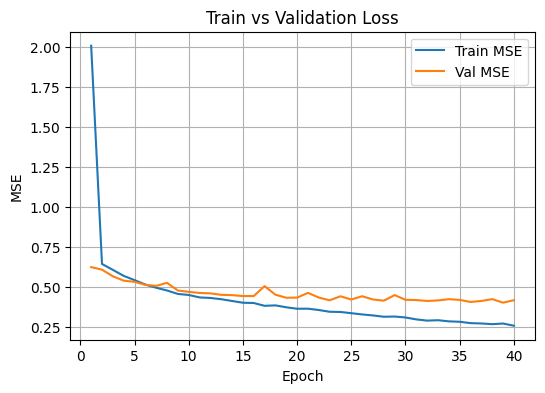

In [26]:
train_loss_list = []
val_loss_list = []

best_val_r2 = -1e9
for epoch in range(1, EPOCHS+1):
    model.train()
    train_losses = []

    for batch in train_loader:
        x = batch['embedding'].to(DEVICE)
        y = batch['mos'].to(DEVICE)
        y_pred = model(x)

        loss = criterion(y_pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())
    train_loss = np.mean(train_losses)
    val_metrics = eval_model(model, val_loader)

    train_loss_list.append(train_loss)
    val_loss_list.append(mean_squared_error(val_metrics['trues'], val_metrics['preds']))

    print(f"Epoch {epoch} | train_loss={train_loss:.4f} | val_r2={val_metrics['r2']:.4f} val_rmse={val_metrics['rmse']:.4f} val_mae={val_metrics['mae']:.4f}")

    if val_metrics['r2'] > best_val_r2:
        best_val_r2 = val_metrics['r2']
        torch.save(model.state_dict(), "/content/wavlm_best_regressor.pt")

plt.figure(figsize=(6,4))
plt.plot(range(1, EPOCHS+1), train_loss_list, label="Train MSE")
plt.plot(range(1, EPOCHS+1), val_loss_list, label="Val MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Train vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
torch.save(model.state_dict(), "/content/drive/MyDrive/models/wavlm_best_regressor.pt")

Test metrics: 0.7197684195789971 0.6319296132689175 0.49587865681715415


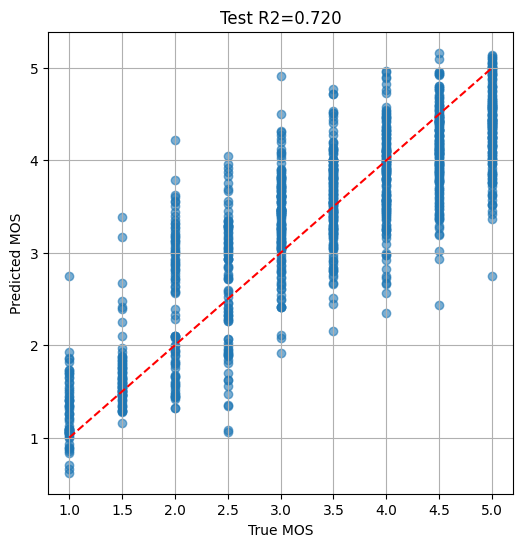

In [29]:
model.load_state_dict(torch.load("/content/drive/MyDrive/models/wavlm_best_regressor.pt"))

test_metrics = eval_model(model, test_loader)
print("Test metrics:", test_metrics['r2'], test_metrics['rmse'], test_metrics['mae'])

plt.figure(figsize=(6,6))
plt.scatter(test_metrics['trues'], test_metrics['preds'], alpha=0.6)
plt.plot([1,5],[1,5], 'r--')
plt.xlabel("True MOS")
plt.ylabel("Predicted MOS")
plt.title(f"Test R2={test_metrics['r2']:.3f}")
plt.grid(True)
plt.show()